In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sb
import PcmPy as pcm
import matplotlib.pyplot as plt
import EFC_learningfMRI.globals as gl
import EFC_learningfMRI.util as util
import EFC_learningfMRI.vis as vis
import EFC_learningfMRI.models as models
import EFC_learningfMRI.G_matrix as mat

base directory found: /cifs/diedrichsen/data/Chord_exp
Atlas directory found: atlases
figure directory found: paper/figures/


In [2]:
H     = 'L'
atlas = 'ROI'
rois  = gl.rois[atlas]
glm   = 3

model_corr = pd.read_csv(os.path.join(gl.baseDir, gl.geomDir, f'model_correlation.within_session.{atlas}.glm{glm}.tsv'), sep='\t')

# one colour per model, shared by every plot below; names are the keys of models.make_G_dict
comp_names = ['type', 'trained', 'untrained', 'mean deviation', 'execution time', 'single finger', 'muscle pattern', 'hand use', 'signed force pattern', 'absolute force pattern', 'force derivative pattern', 'flexion-extension bias', 'mean force magnitude', 'mean force derivative']
chord_models = [c for c in comp_names if c not in ('type', 'trained', 'untrained')]   # properties of the chords themselves
palette   = dict(zip(comp_names, sb.color_palette('tab20', len(comp_names))))   # tab10 would repeat colours past 10 models

# Component model

What each component predicts about the distances between chord patterns.

- **type**: Every trained chord is equally far from every untrained chord, and two chords from the same set (both trained or both untrained) have zero distance.
- **trained**: Trained chords are all equally far from each other, untrained chords have zero distance from each other. 
- **untrained**: Untrained chords are all equally far from each other, trained chords have zero distance from each other.
- **single finger**: Each chord's pattern is the sum of the single-finger patterns of the fingers it uses, taken from Arbuckle et al. (2020).
- **muscle pattern**: Two chords are as far apart as their muscle activity patterns across 10 EMG channels, measured in a separate group of participants (N=5).
- **hand use**: Two chords are close when the finger movements they require often occur together in everyday hand use, as indexed by kinematic (i.e., CyberGlove) recordings from Ingram et al., 2008.
- **signed force pattern**: Distance between chords reflects the distance between their corrsponding signed force patterns.
- **absolute force pattern**: Distance between chords reflects the distance between their corrsponding absolute force patterns.
- **force derivative pattern**: Distance between chords reflects the distance between their corrsponding absolute force derivative patterns.
- **mean deviation**: Distance between chords reflects differences in mean deviation (i.e., chord difficulty) before training (session 4).
- **execution time**: Distance between chords reflects differences in execution time before training (session 4).
- **flexion-extension bias**: Distance between chords reflects their mean signed force, i.e. in whether they lean towards flexion or towards extension.
- **mean force magnitude**: Distance between chords reflects the overall force output required to produce them.
- **mean force derivative**: Distance between chords reflects the overall rate of force variation during their execution.

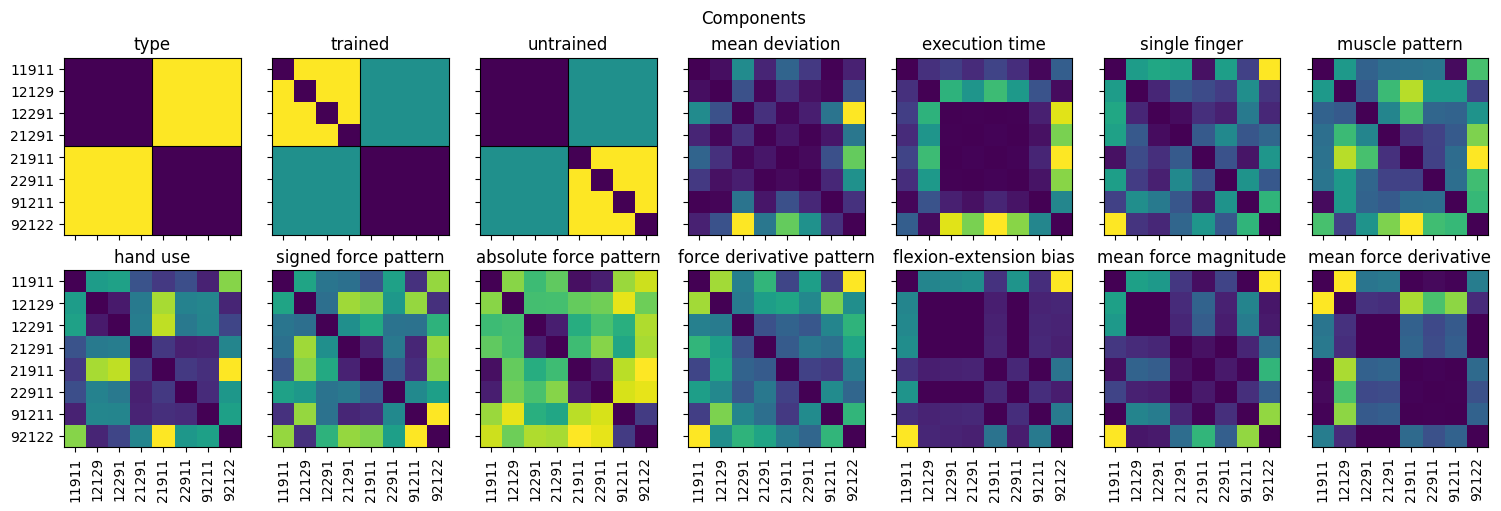

In [3]:
sn = 104
M  = models.make_models(sn, glm=glm, Hem=H, roi=rois[0], comp_names=comp_names)
Mc = M[-2]

chords = np.array(util.get_trained_and_untrained(sn)).astype(int)   # the participant's trained-first order, the order of Mc.Gc

# two rows of 7; no sharex/sharey: shared axes share the tick formatter, so set_xticklabels on one
# panel would relabel all of them, and the panels use two different chord orders
ncols    = 7
nrows    = int(np.ceil(len(comp_names) / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(15, 5), constrained_layout=True, sharex=True, sharey=True)
axs      = axs.ravel()

for i, (G, name) in enumerate(zip(Mc.Gc, comp_names)):
    ax = axs[i]
    if name in chord_models:
        d     = pcm.G_to_dist(mat.G_sorted(G, sn, order=gl.chordID))   # off the participant's trained-first order, onto gl.chordID
        ticks = gl.chordID
    else:
        d     = pcm.G_to_dist(G)                                            # trained-first: the line splits trained from untrained
        ticks = chords
        ax.axhline(3.5, lw=.8, color='k')
        ax.axvline(3.5, lw=.8, color='k')
    ax.imshow(d)
    ax.set_xticks(np.arange(8))
    ax.set_xticklabels(ticks, rotation=90)
    ax.set_yticks(np.arange(8))
    ax.set_yticklabels(ticks)
    ax.set_title(name)

for ax in axs[len(comp_names):]:                                            # hide unused panels if comp_names isn't a multiple of 7
    ax.set_visible(False)

fig.suptitle('Components')

fig.savefig(os.path.join(gl.figDir, 'components.pdf'))

plt.show()

condition number of R: 891.0
                            VIF  R2 from others
type                       2.82            0.65
trained                    3.56            0.72
untrained                  5.49            0.82
mean deviation             3.94            0.75
execution time             9.88            0.90
single finger             26.62            0.96
muscle pattern            42.02            0.98
hand use                  36.67            0.97
signed force pattern      39.95            0.97
absolute force pattern     6.76            0.85
force derivative pattern  40.90            0.98
flexion-extension bias    13.66            0.93
mean force magnitude      14.23            0.93
mean force derivative      7.25            0.86


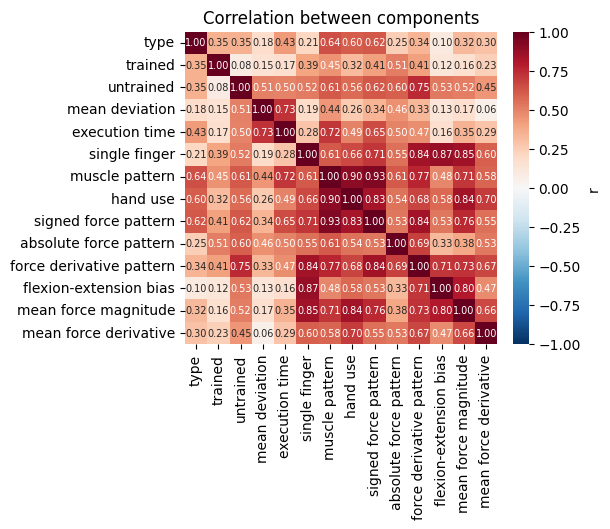

In [4]:
# correlation between the component Gs above (trace-normalised, upper triangle with the diagonal)
iu = np.triu_indices(Mc.Gc.shape[1])
R  = np.corrcoef(np.array([G[iu] for G in Mc.Gc]))

# condition number: one number for the whole set, large when some combination of components is close to another
# VIF = diag(inv(R)) says which component it is: R2 = 1 - 1/VIF is how well the others predict it
print(f'condition number of R: {np.linalg.cond(R):.1f}')
vif = pd.DataFrame({'VIF': np.diag(np.linalg.inv(R))}, index=comp_names)
vif['R2 from others'] = 1 - 1 / vif.VIF
print(vif.round(2))

fig, ax = plt.subplots(figsize=(6, 6), constrained_layout=True)

sb.heatmap(pd.DataFrame(R, index=comp_names, columns=comp_names), ax=ax, vmin=-1, vmax=1, cmap='RdBu_r', annot=True, fmt='.2f', annot_kws={'size': 7}, square=True, cbar_kws={'label': 'r', 'fraction': .05})

ax.set_title(f'Correlation between components')

plt.show()

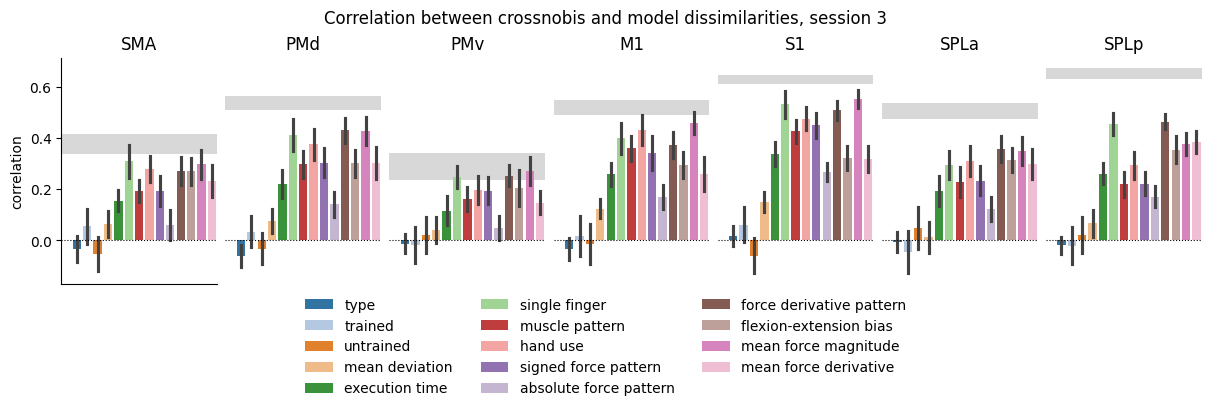

In [5]:
# session 3 only
df = model_corr[(model_corr.Hem == H) & (model_corr.session == 3)]

fig, axs = plt.subplots(1, len(rois), sharey=True, sharex=True, figsize=(12, 4), constrained_layout=True)

vis.plot_im_sess(fig, axs, df, rois, y='r', x='model', hue='model', hue_order=comp_names, palette=palette, kind='bar', native_scale=False, add_zero=True)
vis.add_noise_ceiling(axs, df, rois)
for ax in axs:
    ax.tick_params(bottom=False, labelbottom=False)
axs[0].set_ylabel('correlation')
axs[-1].legend([], frameon=False)
fig.legend(frameon=False, loc='outside lower center', ncol=3)

fig.suptitle('Correlation between crossnobis and model dissimilarities, session 3')

plt.show()

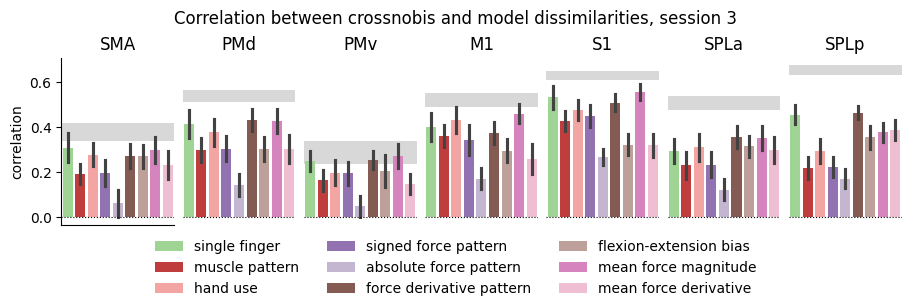

In [6]:
# session 3, structural models only
models_sub = ['single finger', 'muscle pattern', 'hand use',
              'signed force pattern', 'absolute force pattern', 'force derivative pattern',
              'flexion-extension bias', 'mean force magnitude', 'mean force derivative']

df = model_corr[(model_corr.Hem == H) & (model_corr.session == 3)]
df = df[df.model.isin(models_sub)]

fig, axs = plt.subplots(1, len(rois), sharey=True, sharex=True, figsize=(9, 3), constrained_layout=True)

vis.plot_im_sess(fig, axs, df, rois, y='r', x='model', hue='model', order=models_sub,
                 hue_order=models_sub, palette=palette, kind='bar', native_scale=False, add_zero=True)
vis.add_noise_ceiling(axs, df, rois)
for ax in axs:
    ax.tick_params(bottom=False, labelbottom=False)
axs[0].set_ylabel('correlation')
axs[-1].legend([], frameon=False)
fig.legend(frameon=False, loc='outside lower center', ncol=3)

fig.suptitle('Correlation between crossnobis and model dissimilarities, session 3')

plt.show()

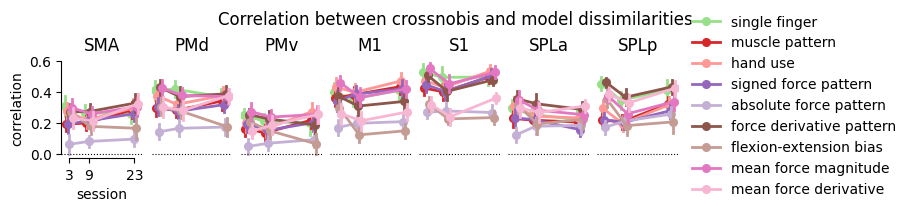

In [7]:
fig, axs = plt.subplots(1, len(rois), sharey=True, sharex=True, figsize=(9, 2), constrained_layout=True)

vis.plot_im_sess(fig, axs, model_corr[model_corr.Hem == H], rois, y='r', x='session', hue='model',
                 hue_order=models_sub, palette=palette, kind='point', dodge=.4, add_zero=True)
sb.despine(ax=axs[0], trim=True)
axs[0].set_ylabel('correlation')
axs[0].set_xlabel('session')
axs[-1].legend([], frameon=False, loc='upper right')
fig.legend(frameon=False, loc='outside right center')

fig.suptitle('Correlation between crossnobis and model dissimilarities')

plt.show()

/localscratch/tmp/ipykernel_1670075/684999754.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  fig.legend(frameon=False, loc='outside right center')


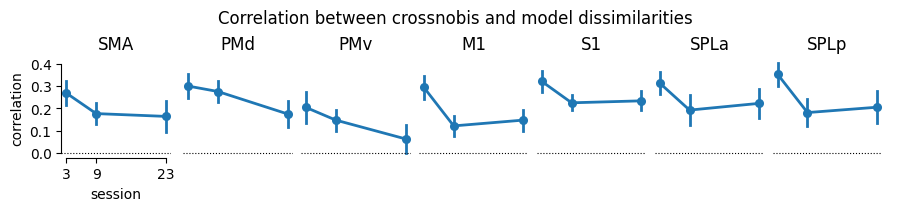

In [8]:
fig, axs = plt.subplots(1, len(rois), sharey=True, sharex=True, figsize=(9, 2), constrained_layout=True)

vis.plot_im_sess(fig, axs, model_corr[(model_corr.Hem == H) & (model_corr.model=='flexion-extension bias')], rois, y='r', x='session', kind='point',add_zero=True)
sb.despine(ax=axs[0], trim=True)
axs[0].set_ylabel('correlation')
axs[0].set_xlabel('session')
axs[-1].legend([], frameon=False, loc='upper right')
fig.legend(frameon=False, loc='outside right center')

fig.suptitle('Correlation between crossnobis and model dissimilarities')

plt.show()